# DailyTalk — Entraînement et évaluation de modèles de reconnaissance vocale (Speech to Text)

Ce notebook fait suite au notebook **EDA + Preprocessing** : il lit les fichiers produits dans
`SpeechToText/data/processed/` (`train.csv`, `validation.csv`, `test.csv` et `audio_16k/*.wav`).

## Quelle tâche entraîner ?
D'après le schéma affiché par l'EDA, la version `eustlb/dailytalk` ne contient que
`conversation_id, turn_id, speaker_id, text, audio, audio_codes` : **il n'y a pas de colonnes `emotion`, `act` ni `topic`**
(d'où `label_maps = {}` dans l'EDA). Il n'y a donc rien à classifier. La tâche supervisée disponible, et celle de votre module,
est la **reconnaissance vocale (ASR)** : audio → texte.

## Modèles comparés
| # | Modèle | Rôle |
|---|---|---|
| 1 | Whisper (ex. `whisper-tiny.en`) **zero-shot** | baseline : le modèle pré-entraîné, sans rien changer |
| 2 | `wav2vec2-base-960h` **zero-shot** | baseline d'une architecture différente (CTC) |
| 3 | Whisper **fine-tuné sur DailyTalk** | le modèle entraîné ici |

Comparer à des baselines zero-shot est indispensable : un WER seul ne dit pas si l'entraînement a servi à quelque chose.

## Métriques
- **WER** (Word Error Rate) = (substitutions + suppressions + insertions) / nombre de mots de référence. Plus bas = mieux.
- **CER** : même chose au niveau des caractères.
- **RTF** (Real-Time Factor) = temps de calcul / durée de l'audio. En dessous de 1, le modèle est plus rapide que le temps réel.

## Pipeline
0. Configuration → 1. Chargement des CSV → 2. Normalisation et métriques → 3. Dataset et fonctions d'inférence →
4. Baselines zero-shot → 5. Fine-tuning de Whisper → 6. Évaluation sur le test → 7. Comparaison et analyse d'erreurs → 8. Sauvegarde

> **Premier lancement :** laissez `MODE = "quick"` (quelques minutes) pour vérifier que tout fonctionne, puis passez à `"full"`.
> L'entraînement complet n'est réaliste que sur GPU (Kaggle, Colab, ou une carte NVIDIA).

In [1]:
# Installation (une seule fois). Pour un GPU NVIDIA, installez d'abord torch depuis https://pytorch.org
%pip install -q torch transformers accelerate jiwer soundfile librosa pandas numpy matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Imports, chemins et configuration

Le notebook retrouve tout seul le dossier `SpeechToText` (comme le notebook EDA), puis range ses sorties dans :
- `SpeechToText/models/` : le modèle fine-tuné (`<modèle>-dailytalk/best/`),
- `SpeechToText/models/results/` : métriques, prédictions et figures.

In [2]:
import dataclasses
import gc
import inspect
import json
import os
import re
import shutil
import time
import unicodedata
from collections import Counter
from pathlib import Path
from typing import Any

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import jiwer
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from tqdm.auto import tqdm
from transformers import (
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    Wav2Vec2ForCTC, Wav2Vec2Processor,
    WhisperForConditionalGeneration, WhisperProcessor,
    set_seed,
)

# ------------------------------------------------------------------ dossier projet SpeechToText
cwd = Path.cwd().resolve()
PROJECT_DIR = next((p for p in [cwd, *cwd.parents] if p.name.lower() == "speechtotext"), None)
if PROJECT_DIR is None and (cwd / "SpeechToText").is_dir():
    PROJECT_DIR = cwd / "SpeechToText"
if PROJECT_DIR is None:
    raise FileNotFoundError("Dossier SpeechToText introuvable. Placez ce notebook dans ml/SpeechToText/notebooks/.")

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
AUDIO_DIR = PROCESSED_DIR / "audio_16k"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = MODELS_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"
for d in (MODELS_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

for s in ("train", "validation", "test"):
    if not (PROCESSED_DIR / f"{s}.csv").exists():
        raise FileNotFoundError(f"{PROCESSED_DIR / (s + '.csv')} introuvable : lancez d'abord le notebook EDA + Preprocessing.")

# ------------------------------------------------------------------ configuration
MODE = "quick"          # "quick" = test rapide du pipeline | "full" = entraînement complet
SEED = 42
TARGET_SR = 16_000

# Modèles Whisper à fine-tuner (chacun est aussi évalué en zero-shot).
# Versions anglaises (".en") : meilleures que les multilingues à taille égale, car DailyTalk est en anglais.
# Pour comparer plusieurs tailles, ajoutez par exemple "openai/whisper-base.en".
FINETUNE_MODELS = ["openai/whisper-tiny.en"]

RUN_WAV2VEC2_BASELINE = True
WAV2VEC2_MODEL = "facebook/wav2vec2-base-960h"
CLEAN_CHECKPOINTS = True   # supprime les checkpoints intermédiaires (centaines de Mo) après l'entraînement

if MODE == "quick":
    N_TRAIN, N_VAL, N_TEST = 300, 100, 150     # sous-échantillons
    VAL_DURING_TRAIN = 100                     # énoncés de validation utilisés pendant l'entraînement
    MAX_STEPS, NUM_EPOCHS = 30, 3.0
    EVAL_STEPS, WARMUP_STEPS = 15, 5
else:
    N_TRAIN = N_VAL = N_TEST = None            # tout le dataset
    VAL_DURING_TRAIN = 500
    MAX_STEPS, NUM_EPOCHS = -1, 3.0            # MAX_STEPS = -1 -> on suit NUM_EPOCHS
    EVAL_STEPS, WARMUP_STEPS = 500, 500

if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
USE_FP16 = DEVICE == "cuda"
TRAIN_BS = 16 if DEVICE == "cuda" else 4
EVAL_BS = 16 if DEVICE == "cuda" else 8

# Taux d'apprentissage de pic recommandés pour Whisper (article original) selon la taille
LR_BY_SIZE = {"tiny": 3.75e-5, "base": 2.5e-5, "small": 1.25e-5, "medium": 6.25e-6}


def lr_for(model_name):
    for size, lr in LR_BY_SIZE.items():
        if size in model_name:
            return lr
    return 1e-5


set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close()


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("Projet   :", PROJECT_DIR)
print("Mode     :", MODE, "| Device :", DEVICE, "| fp16 :", USE_FP16)
print("Modèles  :", FINETUNE_MODELS, "+ wav2vec2" if RUN_WAV2VEC2_BASELINE else "")
if MODE == "full" and DEVICE == "cpu":
    print("⚠️  Mode full sur CPU : l'entraînement prendrait des jours. Utilisez un GPU (Kaggle/Colab) ou gardez MODE='quick'.")

c:\Users\rania\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 07:17:47.922000 4812 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1117 07:17:48.314000 4812 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Projet   : C:\Users\rania\Downloads\ml\SpeechToText
Mode     : quick | Device : cpu | fp16 : False
Modèles  : ['openai/whisper-tiny.en'] + wav2vec2


## 1. Chargement des CSV produits par l'EDA

Points de logique :
- On ne lit que les colonnes utiles (`usecols`) : le CSV contient `audio_codes`, une énorme colonne JSON inutile ici.
- Les chemins `audio_path` ont été écrits en absolu par l'EDA. Si le dossier a été déplacé, on retrouve le WAV par son nom dans `audio_16k/`.
- Le split train/validation/test a déjà été fait **par conversation** (aucune fuite). On le reprend tel quel.

In [3]:
NEEDED = ["conv", "turn", "speaker", "text", "text_clean", "text_norm", "audio_path", "duration", "duration_16k"]


def fix_audio_path(p):
    """Retrouve le WAV même si le projet a été déplacé (chemin Windows ou Linux)."""
    if Path(str(p)).exists():
        return str(p)
    name = re.split(r"[\\/]", str(p))[-1]
    cand = AUDIO_DIR / name
    return str(cand) if cand.exists() else str(p)


def load_split(name, n=None):
    df = pd.read_csv(PROCESSED_DIR / f"{name}.csv", encoding="utf-8-sig", usecols=lambda c: c in NEEDED)
    missing = {"text_clean", "text_norm", "audio_path"} - set(df.columns)
    if missing:
        raise KeyError(f"Colonnes manquantes dans {name}.csv : {missing}")
    df["audio_path"] = df["audio_path"].map(fix_audio_path)
    ok = df["audio_path"].map(lambda p: Path(p).exists())
    if (~ok).any():
        print(f"⚠️  {name} : {(~ok).sum()} fichiers WAV introuvables, ignorés")
    df = df[ok].copy()
    for c in ("text_clean", "text_norm"):
        df[c] = df[c].fillna("").astype(str)
    df = df[df["text_norm"].str.len() > 0]
    if "duration_16k" not in df.columns:
        df["duration_16k"] = df["duration"]
    df["duration_16k"] = df["duration_16k"].fillna(df.get("duration", np.nan))
    if n is not None and len(df) > n:
        df = df.sample(n, random_state=SEED)
    return df.reset_index(drop=True)


train_df = load_split("train", N_TRAIN)
val_df = load_split("validation", N_VAL)
test_df = load_split("test", N_TEST)

for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11}: {len(d):>6} énoncés | {d['duration_16k'].sum() / 3600:.2f} h")

# Vérification rapide d'un fichier audio
info = sf.info(train_df.loc[0, "audio_path"])
print("\nExemple :", info.samplerate, "Hz,", info.channels, "canal(aux),", f"{info.duration:.2f}s")
assert info.samplerate == TARGET_SR, "Les WAV doivent être en 16 kHz (étape 5 de l'EDA)."
train_df[["text_clean", "text_norm", "duration_16k"]].head(5)

train      :    300 énoncés | 0.24 h
validation :    100 énoncés | 0.08 h
test       :    150 énoncés | 0.12 h

Exemple : 16000 Hz, 1 canal(aux), 2.94s


,text_clean,text_norm,duration_16k
0,Are you OK? I didn't mean to put you in danger.,are you ok i didn't mean to put you in danger,2.944
1,What do you want me to do with that paper over...,what do you want me to do with that paper over...,2.400
2,How long have you lived here?,how long have you lived here,1.664
3,"Yes, of course.",yes of course,1.216
4,What kinds of clubs?,what kinds of clubs,1.344


## 2. Normalisation du texte et métriques

**Pourquoi normaliser avant de calculer le WER ?** Whisper écrit « Hello, world! » alors que la référence normalisée est « hello world ».
Sans normalisation, la casse et la ponctuation seraient comptées comme des erreurs. On applique donc **la même fonction `normalize_text`
que dans l'EDA** à la référence et à la prédiction : on mesure ce que le modèle a entendu, pas sa mise en forme.

> Limite connue : si la référence écrit « twenty » et le modèle « 20 », ce sera compté comme une erreur.

In [4]:
def clean_text(t: str) -> str:
    t = unicodedata.normalize("NFKC", t)
    t = (t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
          .replace("…", "...").replace("–", "-").replace("—", "-"))
    return re.sub(r"\s+", " ", t).strip()


def normalize_text(t: str) -> str:
    """Identique à l'EDA : minuscules, sans ponctuation (apostrophes conservées)."""
    t = clean_text(t).lower()
    t = re.sub(r"[^a-z0-9' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def wer_cer(refs, hyps):
    """WER et CER en %, en ignorant les références vides (sans mot à comparer)."""
    pairs = [(r, h) for r, h in zip(refs, hyps) if r.strip()]
    r, h = [p[0] for p in pairs], [p[1] for p in pairs]
    return jiwer.wer(r, h) * 100, jiwer.cer(r, h) * 100


# Tests de cohérence
assert normalize_text("Hello, World!") == "hello world"
w, c = wer_cer(["the cat sat"], ["the cat sit"])
print(f"WER de contrôle : {w:.1f}% (attendu 33.3%) | CER : {c:.1f}%")

WER de contrôle : 33.3% (attendu 33.3%) | CER : 9.1%


## 3. Dataset PyTorch, collator et fonctions d'inférence

**Pourquoi ne pas utiliser `datasets.Audio` ?** Les versions récentes de `datasets` décodent l'audio via `torchcodec` + FFmpeg, une source d'erreurs sous Windows.
Les WAV sont déjà en 16 kHz mono : on les lit directement avec `soundfile`, dans un `Dataset` PyTorch classique qui calcule les features **à la volée**
(rien n'est gardé en mémoire, 19 000 spectrogrammes ne tiendraient pas en RAM).

**Le collator** assemble un batch : il complète les features, complète les textes (tokens) avec `-100` (valeur ignorée par la loss) et retire
le token de début s'il a été ajouté deux fois.

In [5]:
def load_wav(path):
    y, sr = sf.read(path, dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)
    return y


class WhisperDataset(torch.utils.data.Dataset):
    """Retourne les log-mel features (80 x 3000) et les tokens du texte cible (avec casse et ponctuation)."""

    def __init__(self, df, processor):
        self.paths = df["audio_path"].tolist()
        self.texts = df["text_clean"].tolist()
        self.fe, self.tok = processor.feature_extractor, processor.tokenizer

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        feats = self.fe(load_wav(self.paths[i]), sampling_rate=TARGET_SR).input_features[0]
        labels = self.tok(self.texts[i]).input_ids[:440]
        return {"input_features": feats, "labels": labels}


@dataclasses.dataclass
class SpeechSeq2SeqCollator:
    processor: Any
    decoder_start_token_id: int

    def __call__(self, features):
        batch = self.processor.feature_extractor.pad(
            [{"input_features": f["input_features"]} for f in features], return_tensors="pt")
        labels_batch = self.processor.tokenizer.pad(
            [{"input_ids": f["labels"]} for f in features], return_tensors="pt")
        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)
        # Le modèle ajoute lui-même le token de début : on ne le garde pas deux fois
        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

In [6]:
def is_multilingual(model_name):
    return not model_name.endswith(".en")


def short_name(model_name):
    return model_name.rstrip("/").split("/")[-1]


@torch.no_grad()
def transcribe_whisper(model, processor, paths, batch_size, multilingual, desc="Whisper"):
    model.to(DEVICE).eval()
    hyps = []
    for i in tqdm(range(0, len(paths), batch_size), desc=desc):
        wavs = [load_wav(p) for p in paths[i:i + batch_size]]
        feats = processor.feature_extractor(wavs, sampling_rate=TARGET_SR, return_tensors="pt").input_features.to(DEVICE)
        gen_kwargs = dict(max_new_tokens=128, num_beams=1, do_sample=False)
        if multilingual:
            gen_kwargs.update(language="en", task="transcribe")
        with torch.autocast(device_type="cuda" if DEVICE == "cuda" else "cpu", enabled=USE_FP16):
            ids = model.generate(input_features=feats, **gen_kwargs)
        hyps += processor.batch_decode(ids, skip_special_tokens=True)
    return [h.strip() for h in hyps]


@torch.no_grad()
def transcribe_wav2vec2(paths, batch_size, desc="wav2vec2"):
    processor = Wav2Vec2Processor.from_pretrained(WAV2VEC2_MODEL)
    model = Wav2Vec2ForCTC.from_pretrained(WAV2VEC2_MODEL).to(DEVICE).eval()
    hyps = []
    for i in tqdm(range(0, len(paths), batch_size), desc=desc):
        wavs = [load_wav(p) for p in paths[i:i + batch_size]]
        inputs = processor(wavs, sampling_rate=TARGET_SR, return_tensors="pt", padding=True)
        logits = model(inputs.input_values.to(DEVICE)).logits
        hyps += processor.batch_decode(torch.argmax(logits, dim=-1))   # sortie en MAJUSCULES, sans ponctuation
    del model
    free_memory()
    return [h.strip() for h in hyps]


# Registre des résultats : HYPS[nom] = prédictions brutes sur le jeu de test
HYPS, results = {}, []
TEST_AUDIO_SECONDS = float(test_df["duration_16k"].sum())


def register(name, kind, hyps, seconds):
    """Calcule WER/CER sur le jeu de test (après normalisation) et enregistre le modèle."""
    wer, cer = wer_cer(test_df["text_norm"].tolist(), [normalize_text(h) for h in hyps])
    HYPS[name] = hyps
    results.append({"modèle": name, "type": kind, "WER (%)": round(wer, 2), "CER (%)": round(cer, 2),
                    "RTF": round(seconds / TEST_AUDIO_SECONDS, 3), "n_test": len(test_df)})
    print(f"{name:<38} WER {wer:6.2f}% | CER {cer:6.2f}% | RTF {seconds / TEST_AUDIO_SECONDS:.3f}")

## 4. Baselines zero-shot (modèles pré-entraînés, sans entraînement)

Ces résultats sont le **point de comparaison** : le fine-tuning n'est utile que s'il fait mieux que ces modèles tels quels.

In [7]:
test_paths = test_df["audio_path"].tolist()

# --- Whisper zero-shot (un par modèle de FINETUNE_MODELS)
for name in FINETUNE_MODELS:
    processor = WhisperProcessor.from_pretrained(name)
    model = WhisperForConditionalGeneration.from_pretrained(name)
    t0 = time.perf_counter()
    hyps = transcribe_whisper(model, processor, test_paths, EVAL_BS, is_multilingual(name), f"{short_name(name)} zero-shot")
    register(f"{short_name(name)} (zero-shot)", "zero-shot", hyps, time.perf_counter() - t0)
    del model, processor
    free_memory()

# --- wav2vec2 zero-shot
if RUN_WAV2VEC2_BASELINE:
    t0 = time.perf_counter()
    hyps = transcribe_wav2vec2(test_paths, EVAL_BS)
    register(f"{short_name(WAV2VEC2_MODEL)} (zero-shot)", "zero-shot", hyps, time.perf_counter() - t0)

pd.DataFrame(results)

whisper-tiny.en zero-shot:   0%|          | 0/19 [00:00<?, ?it/s][transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
[transformers] Both `max_new_tokens` (=128) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transfo

whisper-tiny.en (zero-shot)            WER  10.42% | CER   5.60% | RTF 0.202


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 467.24it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
wav2vec2: 100%|██████████| 19/19 [01:50<00:00,  5.83s/it]


wav2vec2-base-960h (zero-shot)         WER  18.21% | CER   6.98% | RTF 0.453


,modèle,type,WER (%),CER (%),RTF,n_test
0,whisper-tiny.en (zero-shot),zero-shot,10.42,5.60,0.202,150
1,wav2vec2-base-960h (zero-shot),zero-shot,18.21,6.98,0.453,150


## 5. Fine-tuning de Whisper

**Logique de l'entraînement**
- Whisper est un modèle encodeur-décodeur : l'encodeur transforme le spectrogramme, le décodeur génère le texte mot à mot.
  On l'entraîne à prédire `text_clean` (avec casse et ponctuation) à partir de l'audio, avec une loss d'entropie croisée.
- **Taux d'apprentissage faible** (de l'ordre de 1e-5) : on *adapte* un modèle déjà très bon, on ne le réapprend pas. Un taux trop élevé détruirait ses connaissances.
- **Warmup** : le taux monte progressivement au début, pour éviter des mises à jour brutales.
- **Évaluation pendant l'entraînement** sur un sous-ensemble de validation (génération = lent), et on **garde le meilleur checkpoint** (WER de validation le plus bas),
  pas le dernier : cela limite le surapprentissage.
- Le jeu de **test n'est jamais vu** pendant l'entraînement ni pour choisir le checkpoint.

In [8]:
def make_args(cls, **kw):
    """Construit des TrainingArguments en ignorant les options absentes de la version de transformers installée."""
    valid = {f.name for f in dataclasses.fields(cls)}
    if "eval_strategy" in kw and "eval_strategy" not in valid and "evaluation_strategy" in valid:
        kw["evaluation_strategy"] = kw.pop("eval_strategy")      # ancien nom (transformers < 4.41)
    dropped = [k for k in kw if k not in valid]
    if dropped:
        print("Options ignorées par cette version de transformers :", dropped)
    return cls(**{k: v for k, v in kw.items() if k in valid})


def finetune_whisper(name):
    short = short_name(name)
    out_dir = MODELS_DIR / f"{short}-dailytalk"
    best_dir = out_dir / "best"
    multi = is_multilingual(name)

    processor = WhisperProcessor.from_pretrained(name)
    if multi:
        processor.tokenizer.set_prefix_tokens(language="english", task="transcribe")
    model = WhisperForConditionalGeneration.from_pretrained(name)
    model.config.forced_decoder_ids = None
    model.generation_config.forced_decoder_ids = None
    if multi:
        model.generation_config.language, model.generation_config.task = "english", "transcribe"

    val_small = val_df.sample(min(VAL_DURING_TRAIN, len(val_df)), random_state=SEED).reset_index(drop=True)
    train_ds, val_ds = WhisperDataset(train_df, processor), WhisperDataset(val_small, processor)
    collator = SpeechSeq2SeqCollator(processor, model.config.decoder_start_token_id)
    pad_id = processor.tokenizer.pad_token_id

    def compute_metrics(pred):
        pred_ids, label_ids = pred.predictions, np.array(pred.label_ids)
        if isinstance(pred_ids, tuple):
            pred_ids = pred_ids[0]
        pred_ids = np.where(np.array(pred_ids) == -100, pad_id, pred_ids)   # le Trainer remplit avec -100
        label_ids = np.where(label_ids == -100, pad_id, label_ids)
        pred_str = [normalize_text(s) for s in processor.batch_decode(pred_ids, skip_special_tokens=True)]
        label_str = [normalize_text(s) for s in processor.batch_decode(label_ids, skip_special_tokens=True)]
        w, c = wer_cer(label_str, pred_str)
        return {"wer": w, "cer": c}

    args = make_args(
        Seq2SeqTrainingArguments,
        output_dir=str(out_dir / "checkpoints"),
        per_device_train_batch_size=TRAIN_BS, per_device_eval_batch_size=EVAL_BS,
        learning_rate=lr_for(name), warmup_steps=WARMUP_STEPS,
        max_steps=MAX_STEPS, num_train_epochs=NUM_EPOCHS,
        fp16=USE_FP16,
        eval_strategy="steps", eval_steps=EVAL_STEPS,
        save_strategy="steps", save_steps=EVAL_STEPS, save_total_limit=2,
        logging_steps=max(1, EVAL_STEPS // 5),
        predict_with_generate=True, generation_max_length=128,
        load_best_model_at_end=True, metric_for_best_model="wer", greater_is_better=False,
        report_to="none", remove_unused_columns=False, label_names=["labels"],
        dataloader_num_workers=0, seed=SEED,
    )

    trainer_kwargs = dict(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=collator, compute_metrics=compute_metrics)
    # transformers >= 4.46 : "processing_class" remplace "tokenizer"
    if "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters:
        trainer_kwargs["processing_class"] = processor.feature_extractor
    else:
        trainer_kwargs["tokenizer"] = processor.feature_extractor
    trainer = Seq2SeqTrainer(**trainer_kwargs)

    print(f"\n=== Fine-tuning {short} | lr={lr_for(name)} | {len(train_ds)} énoncés ===")
    trainer.train()

    best_dir.mkdir(parents=True, exist_ok=True)
    trainer.save_model(str(best_dir))
    processor.save_pretrained(str(best_dir))
    history = pd.DataFrame(trainer.state.log_history)
    history.to_csv(out_dir / "training_log.csv", index=False)
    if CLEAN_CHECKPOINTS:
        shutil.rmtree(out_dir / "checkpoints", ignore_errors=True)
    return trainer.model, processor, history, best_dir


histories, best_dirs, finetuned_models = {}, {}, {}
for name in FINETUNE_MODELS:
    model, processor, history, best_dir = finetune_whisper(name)
    histories[short_name(name)], best_dirs[short_name(name)] = history, best_dir
    finetuned_models[name] = (model, processor)
    print("Modèle sauvegardé dans :", best_dir)

Loading weights: 100%|██████████| 167/167 [00:00<00:00, 1296.32it/s]



=== Fine-tuning whisper-tiny.en | lr=3.75e-05 | 300 énoncés ===


c:\Users\rania\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss,Validation Loss,Wer,Cer
15,0.357298,0.394276,12.251656,5.981524
30,0.454139,0.307870,10.927152,5.704388


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.65it/s]
c:\Users\rania\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.71it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['proj_out.weight'].
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it]


Modèle sauvegardé dans : C:\Users\rania\Downloads\ml\SpeechToText\models\whisper-tiny.en-dailytalk\best


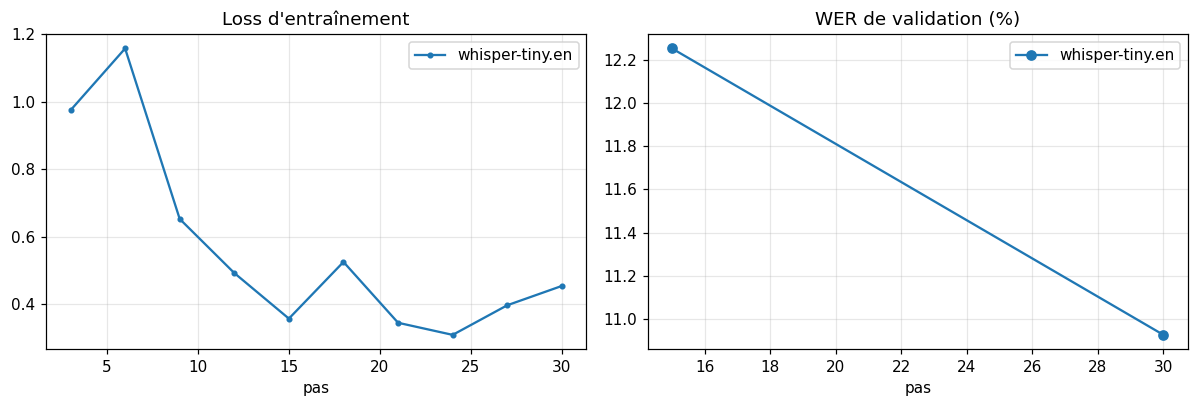

In [9]:
# Courbes d'entraînement : loss d'entraînement et WER de validation
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for short, h in histories.items():
    if "loss" in h.columns:
        t = h.dropna(subset=["loss"])
        axes[0].plot(t["step"], t["loss"], marker="o", ms=3, label=short)
    if "eval_wer" in h.columns:
        e = h.dropna(subset=["eval_wer"])
        axes[1].plot(e["step"], e["eval_wer"], marker="o", label=short)
axes[0].set_title("Loss d'entraînement"); axes[0].set_xlabel("pas"); axes[0].legend()
axes[1].set_title("WER de validation (%)"); axes[1].set_xlabel("pas"); axes[1].legend()
savefig("training_curves")

## 6. Évaluation des modèles fine-tunés sur le jeu de test

In [10]:
for name, (model, processor) in finetuned_models.items():
    t0 = time.perf_counter()
    hyps = transcribe_whisper(model, processor, test_paths, EVAL_BS, is_multilingual(name), f"{short_name(name)} fine-tuné")
    register(f"{short_name(name)} (fine-tuné)", "fine-tuné", hyps, time.perf_counter() - t0)

finetuned_models.clear()
free_memory()
results_df = pd.DataFrame(results).sort_values("WER (%)").reset_index(drop=True)
results_df

whisper-tiny.en fine-tuné: 100%|██████████| 19/19 [01:51<00:00,  5.86s/it]


whisper-tiny.en (fine-tuné)            WER  10.34% | CER   5.02% | RTF 0.257


,modèle,type,WER (%),CER (%),RTF,n_test
0,whisper-tiny.en (fine-tuné),fine-tuné,10.34,5.02,0.257,150
1,whisper-tiny.en (zero-shot),zero-shot,10.42,5.60,0.202,150
2,wav2vec2-base-960h (zero-shot),zero-shot,18.21,6.98,0.453,150


## 7. Comparaison et analyse d'erreurs

Le WER global cache beaucoup de choses. On regarde :
1. la **comparaison** des modèles (WER, CER),
2. le **type** d'erreurs (substitutions, suppressions, insertions),
3. la **durée** des énoncés (les phrases très courtes sont plus difficiles : un mot faux pèse très lourd),
4. le **locuteur**,
5. les **pires énoncés** et les **mots les plus confondus**.

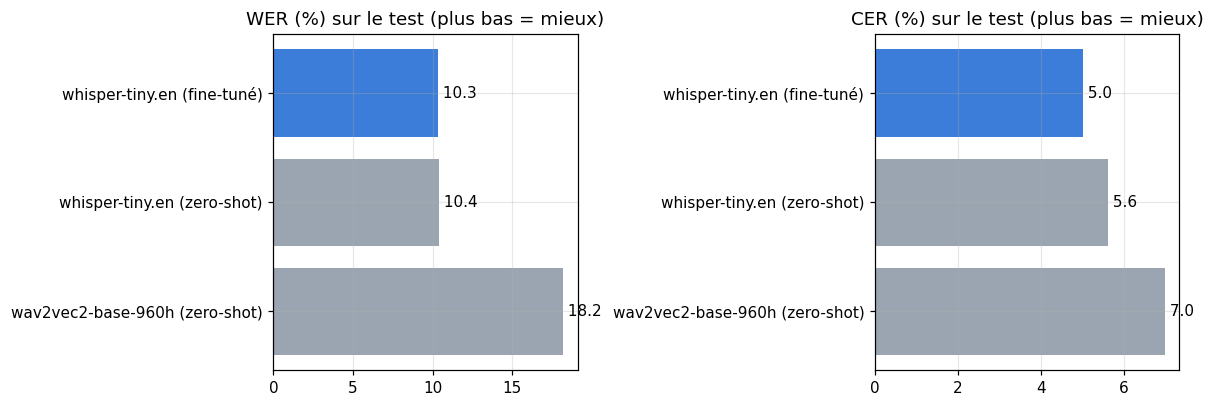

Meilleur modèle : whisper-tiny.en (fine-tuné)


In [11]:
colors = {"zero-shot": "#9aa5b1", "fine-tuné": "#3b7dd8"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["WER (%)", "CER (%)"]):
    ax.barh(results_df["modèle"][::-1], results_df[metric][::-1],
            color=[colors[t] for t in results_df["type"][::-1]])
    for y, v in enumerate(results_df[metric][::-1]):
        ax.text(v, y, f" {v:.1f}", va="center")
    ax.set_title(metric + " sur le test (plus bas = mieux)")
savefig("comparison_wer_cer")

best_name = results_df.loc[0, "modèle"]
print("Meilleur modèle :", best_name)

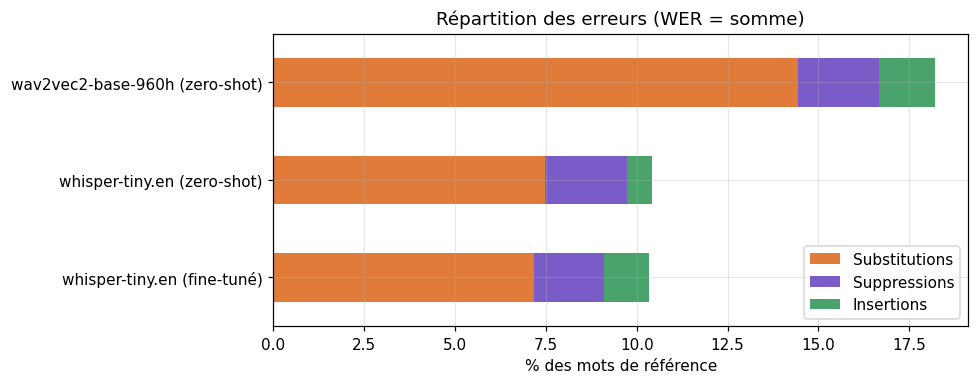

,Substitutions,Suppressions,Insertions
whisper-tiny.en (fine-tuné),7.18,1.93,1.23
whisper-tiny.en (zero-shot),7.48,2.24,0.69
wav2vec2-base-960h (zero-shot),14.43,2.24,1.54


In [12]:
# --- Répartition des erreurs : substitutions / suppressions / insertions (en % des mots de référence)
refs_norm = test_df["text_norm"].tolist()
HN = {name: [normalize_text(h) for h in hyps] for name, hyps in HYPS.items()}   # hypothèses normalisées


def error_breakdown(refs, hyps):
    pairs = [(r, h) for r, h in zip(refs, hyps) if r.strip()]
    out = jiwer.process_words([p[0] for p in pairs], [p[1] for p in pairs])
    n_ref = out.hits + out.substitutions + out.deletions
    return {"Substitutions": 100 * out.substitutions / n_ref, "Suppressions": 100 * out.deletions / n_ref,
            "Insertions": 100 * out.insertions / n_ref}


breakdown = pd.DataFrame({name: error_breakdown(refs_norm, h) for name, h in HN.items()}).T.loc[results_df["modèle"]]
breakdown.plot.barh(stacked=True, figsize=(9, 3.6), color=["#e07b39", "#7a5cc9", "#4aa36b"])
plt.xlabel("% des mots de référence"); plt.title("Répartition des erreurs (WER = somme)")
savefig("error_breakdown")
breakdown.round(2)

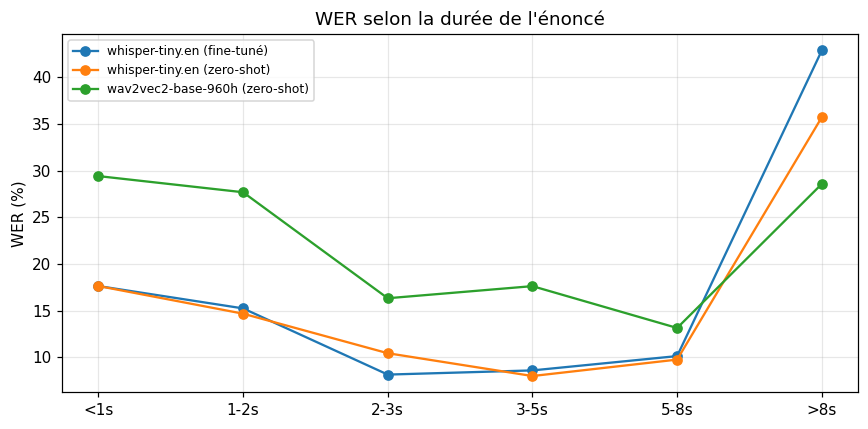

,durée,n,whisper-tiny.en (zero-shot),wav2vec2-base-960h (zero-shot),whisper-tiny.en (fine-tuné)
0,<1s,14,17.6,29.4,17.6
1,1-2s,37,14.7,27.7,15.3
2,2-3s,36,10.5,16.3,8.2
3,3-5s,46,8.0,17.6,8.6
4,5-8s,16,9.8,13.2,10.2
5,>8s,1,35.7,28.6,42.9


,speaker,n,whisper-tiny.en (zero-shot),wav2vec2-base-960h (zero-shot),whisper-tiny.en (fine-tuné)
0,0,76,14.0,21.2,12.8
1,1,74,6.7,15.1,7.8


In [13]:
# --- WER selon la durée de l'énoncé et selon le locuteur
test_df["durée"] = pd.cut(test_df["duration_16k"], bins=[0, 1, 2, 3, 5, 8, 1e9],
                          labels=["<1s", "1-2s", "2-3s", "3-5s", "5-8s", ">8s"])


def group_wer(by):
    rows = []
    for key, idx in test_df.groupby(by, observed=True).groups.items():
        idx = list(idx)
        row = {by: key, "n": len(idx)}
        for name, h in HN.items():
            row[name] = wer_cer([refs_norm[i] for i in idx], [h[i] for i in idx])[0]
        rows.append(row)
    return pd.DataFrame(rows)


by_dur = group_wer("durée")
fig, ax = plt.subplots(figsize=(8, 4))
for name in results_df["modèle"]:
    ax.plot(by_dur["durée"].astype(str), by_dur[name], marker="o", label=name)
ax.set_ylabel("WER (%)"); ax.set_title("WER selon la durée de l'énoncé"); ax.legend(fontsize=8)
savefig("wer_by_duration")
display(by_dur.round(1))

if "speaker" in test_df.columns:
    by_spk = group_wer("speaker")
    display(by_spk.round(1))

Pires énoncés (whisper-tiny.en (fine-tuné)) :


,text_norm,hyp_best,wer_best,duration_16k
117,big head,bighead,100.0,0.7
125,there're beijing roast duck,they are beijing roadstuck,100.0,1.5
102,is it faster if i take highland avenue,is it fast or if i take high length of a new,87.5,2.4
32,one ninety yuan,one nine even,66.7,1.1
10,you are welcome,you're welcome,66.7,0.8
0,how have you been,how are you,50.0,1.0
9,twenty dollars per dozen,20 per dozen,50.0,1.6
40,of course how're you,of course how are you,50.0,1.5
27,then i'll take it,then i will take it,50.0,1.1
96,umm just this suitcase,um just a suitcase,50.0,2.0


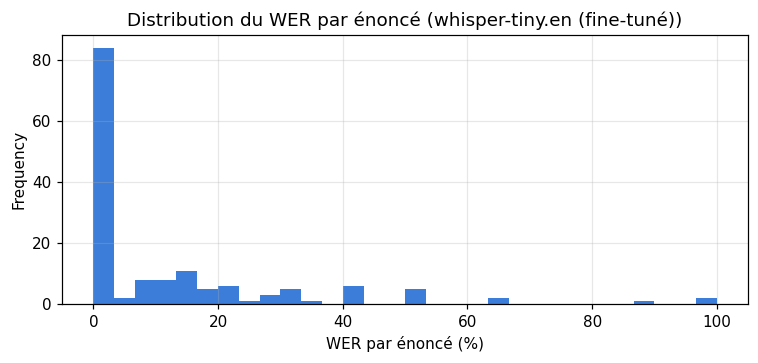

Énoncés transcrits parfaitement : 56.0%

Substitutions les plus fréquentes : [('umm -> um', 5), ('umm -> mmm', 3), ('twenty -> 20', 2), ("you -> you're", 2), ("i -> i'm", 2), ('have -> are', 1), ('hundred -> 100', 1), ('vase -> ways', 1), ('the -> ale', 1), ('stock -> stuff', 1), ('hum -> um', 1), ('racketball -> ball', 1)]
Mots les plus supprimés           : [('will', 3), ('umm', 2), ('are', 2), ('am', 2), ('been', 1), ('hotel', 1), ('dollars', 1), ('er', 1), ('hundred', 1), ('percent', 1), ('kid', 1), ('food', 1)]
Mots les plus insérés             : [('i', 2), ('rock', 1), ('up', 1), ('your', 1), ('part', 1), ('how', 1), ('me', 1), ('pray', 1), ('gear', 1), ('fast', 1), ('high', 1), ('length', 1)]


In [14]:
# --- Pires énoncés et mots les plus confondus pour le meilleur modèle
best_hyps = HN[best_name]
test_df["wer_best"] = [jiwer.wer(r, h) * 100 if r.strip() else np.nan for r, h in zip(refs_norm, best_hyps)]
test_df["hyp_best"] = best_hyps

print(f"Pires énoncés ({best_name}) :")
display(test_df.sort_values("wer_best", ascending=False)[["text_norm", "hyp_best", "wer_best", "duration_16k"]].head(10).round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
test_df["wer_best"].clip(upper=150).plot.hist(bins=30, ax=ax, color="#3b7dd8")
ax.set_xlabel("WER par énoncé (%)"); ax.set_title(f"Distribution du WER par énoncé ({best_name})")
savefig("wer_per_utterance")
print(f"Énoncés transcrits parfaitement : {(test_df['wer_best'] == 0).mean():.1%}")


def word_errors(refs, hyps, top=12):
    pairs = [(r, h) for r, h in zip(refs, hyps) if r.strip()]
    out = jiwer.process_words([p[0] for p in pairs], [p[1] for p in pairs])
    subs, dels, ins = Counter(), Counter(), Counter()
    for i, chunks in enumerate(out.alignments):
        rw, hw = out.references[i], out.hypotheses[i]
        for ch in chunks:
            if ch.type == "substitute":
                for a, b in zip(rw[ch.ref_start_idx:ch.ref_end_idx], hw[ch.hyp_start_idx:ch.hyp_end_idx]):
                    subs[f"{a} -> {b}"] += 1
            elif ch.type == "delete":
                dels.update(rw[ch.ref_start_idx:ch.ref_end_idx])
            elif ch.type == "insert":
                ins.update(hw[ch.hyp_start_idx:ch.hyp_end_idx])
    return subs.most_common(top), dels.most_common(top), ins.most_common(top)


subs, dels, ins = word_errors(refs_norm, best_hyps)
print("\nSubstitutions les plus fréquentes :", subs)
print("Mots les plus supprimés           :", dels)
print("Mots les plus insérés             :", ins)

## 8. Sauvegarde des résultats et utilisation du modèle

Sorties dans `SpeechToText/models/results/` :
- `summary.csv` et `metrics.json` : comparaison des modèles et configuration utilisée,
- `predictions_test.csv` : référence + prédiction de chaque modèle pour chaque énoncé de test,
- `figures/*.png`.

Le modèle fine-tuné est dans `SpeechToText/models/<modèle>-dailytalk/best/`.

In [15]:
results_df.to_csv(RESULTS_DIR / "summary.csv", index=False, encoding="utf-8-sig")

pred_df = test_df[[c for c in ["conv", "turn", "speaker", "audio_path", "duration_16k", "text_clean", "text_norm"] if c in test_df.columns]].copy()
for name, hyps in HYPS.items():
    pred_df[f"hyp | {name}"] = hyps
pred_df.to_csv(RESULTS_DIR / "predictions_test.csv", index=False, encoding="utf-8-sig")

metrics = {
    "mode": MODE, "device": DEVICE, "seed": SEED,
    "data": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    "config": {"finetune_models": FINETUNE_MODELS, "max_steps": MAX_STEPS, "num_epochs": NUM_EPOCHS,
               "train_batch_size": TRAIN_BS, "eval_steps": EVAL_STEPS, "warmup_steps": WARMUP_STEPS,
               "learning_rates": {short_name(n): lr_for(n) for n in FINETUNE_MODELS}},
    "results": results_df.to_dict(orient="records"),
    "best_model": best_name,
    "error_breakdown": breakdown.round(3).to_dict(orient="index"),
    "wer_by_duration": by_dur.round(3).astype({"durée": str}).to_dict(orient="records"),
}
with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False, default=str)

print("✅ Résultats enregistrés dans :", RESULTS_DIR)
print(" - summary.csv, metrics.json, predictions_test.csv, figures/*.png")
for short, d in best_dirs.items():
    print(f" - modèle {short} : {d}")

✅ Résultats enregistrés dans : C:\Users\rania\Downloads\ml\SpeechToText\models\results
 - summary.csv, metrics.json, predictions_test.csv, figures/*.png
 - modèle whisper-tiny.en : C:\Users\rania\Downloads\ml\SpeechToText\models\whisper-tiny.en-dailytalk\best


### Utiliser le modèle sauvegardé

Cette fonction est la base du `predict()` de votre module : elle recharge le modèle depuis le disque (sans réentraîner) et transcrit un fichier audio.

In [16]:
def load_asr(model_dir):
    processor = WhisperProcessor.from_pretrained(model_dir)
    model = WhisperForConditionalGeneration.from_pretrained(model_dir).to(DEVICE).eval()
    return model, processor


def transcribe_file(audio_path, model, processor, multilingual=False):
    return transcribe_whisper(model, processor, [str(audio_path)], 1, multilingual, desc="transcription")[0]


# Démonstration sur 3 énoncés du jeu de test
short0 = short_name(FINETUNE_MODELS[0])
asr_model, asr_processor = load_asr(best_dirs[short0])
for _, row in test_df.sample(3, random_state=SEED).iterrows():
    print("Référence  :", row["text_clean"])
    print("Prédiction :", transcribe_file(row["audio_path"], asr_model, asr_processor, is_multilingual(FINETUNE_MODELS[0])), "\n")

Loading weights: 100%|██████████| 167/167 [00:00<00:00, 1082.44it/s]


Référence  : No. I take public transportation. It's safer.


transcription: 100%|██████████| 1/1 [00:01<00:00,  1.42s/it]


Prédiction : No. I take public transportation. It's safer. 

Référence  : Ah... hence the buns and condiments we bought. And this is Holly's potato salad.


transcription: 100%|██████████| 1/1 [00:01<00:00,  1.78s/it]


Prédiction : Aah, hence the buns and condiments we bought, and this is wholly potato salad. 

Référence  : Ah yes, I can see it now. Where are the cups?


transcription: 100%|██████████| 1/1 [00:01<00:00,  1.25s/it]

Prédiction : Ah, yes. I can see now. Where are the cops? 



## Pour aller plus loin
- **Passer en `MODE = "full"`** sur GPU, puis ajouter `"openai/whisper-base.en"` ou `"openai/whisper-small.en"` dans `FINETUNE_MODELS` pour comparer les tailles.
- **Utiliser le contexte du dialogue** : la colonne `context` (3 tours précédents) peut servir de *prompt* à Whisper pour mieux transcrire les énoncés courts (« Yes. », « Okay. »).
- **Augmentation de données** (bruit, vitesse) si le modèle fine-tuné surapprend (WER d'entraînement bien plus bas que celui de validation).
- **Corriger les erreurs récurrentes** repérées dans l'analyse (nombres écrits en lettres ou en chiffres, noms propres).